In [1]:
# TP ICAP - Rates Market Revenue Analysis
# Objective: Explore how market conditions relate to broking revenue.
# Approach: Statistical analysis, regression and time-series modelling.
#conda install pandas numpy matplotlib ipykernel
#(emrisk) C:\Users\User>
#jupyter notebook

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
#US 2-year Treasury yield (DGS2)
#US 10-year Treasury yield (DGS10)

fred_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS2,DGS10"
market_data = pd.read_csv(fred_url)    #market_data stores the resulting dataset as a Pandas table

In [3]:
market_data.info()
#DGS2 has 4,314 missing values.
#DGS10 has 722 missing values.

<class 'pandas.DataFrame'>
RangeIndex: 16923 entries, 0 to 16922
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  16923 non-null  str    
 1   DGS2              12609 non-null  float64
 2   DGS10             16201 non-null  float64
dtypes: float64(2), str(1)
memory usage: 396.8 KB


In [4]:
# Keep only observations where both Treasury yields are available
clean_data = market_data.dropna(subset=["DGS2", "DGS10"]).copy()

# Convert observation_date from text into dates
clean_data ["observation_date"] = pd.to_datetime(clean_data ["observation_date"])

# Sort observations chronologically
clean_data = clean_data.sort_values("observation_date")

# Check the cleaned dataset
print(clean_data.shape)
print(clean_data.isnull().sum())

# Check the earliest and latest dates
print("Earliest date:", clean_data["observation_date"].min())
print("Latest date:", clean_data["observation_date"].max())

(12609, 3)
observation_date    0
DGS2                0
DGS10               0
dtype: int64
Earliest date: 1976-06-01 00:00:00
Latest date: 2026-11-12 00:00:00


In [5]:
clean_data.head(5)

,observation_date,DGS2,DGS10
3760,1976-06-01,7.26,7.94
3761,1976-06-02,7.23,7.94
3762,1976-06-03,7.22,7.92
3763,1976-06-04,7.12,7.89
3764,1976-06-07,7.09,7.88


In [6]:
# Display all variables currently stored in your notebook
%whos

Variable      Type         Data/Info
------------------------------------
clean_data    DataFrame    Shape: (12609, 3)
fred_url      str          https://fred.stlouisfed.o<...>edgraph.csv?id=DGS2,DGS10
market_data   DataFrame    Shape: (16923, 3)
mdates        module       <module 'matplotlib.dates<...>s\\matplotlib\\dates.py'>
np            module       <module 'numpy' from 'C:\<...>ges\\numpy\\__init__.py'>
pd            module       <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plt           module       <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>


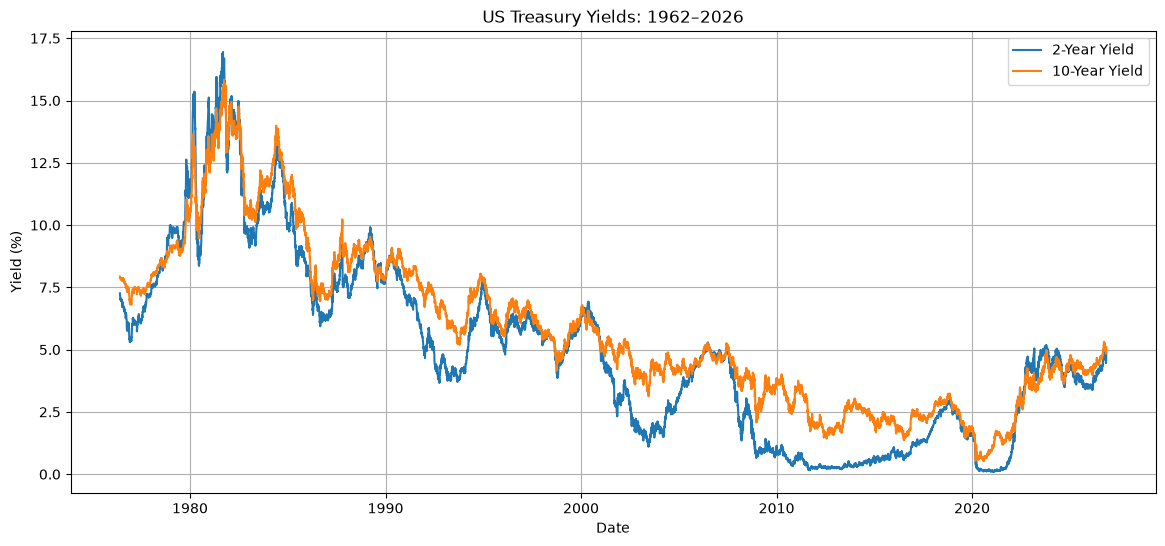

In [7]:
import matplotlib.pyplot as plt
# Plot the 2-year and 10-year Treasury yields
plt.figure(figsize=(14, 6))

plt.plot(clean_data["observation_date"], clean_data["DGS2"], label="2-Year Yield")
plt.plot(clean_data["observation_date"], clean_data["DGS10"], label="10-Year Yield")

plt.title("US Treasury Yields: 1962–2026")
plt.xlabel("Date")
plt.ylabel("Yield (%)")
plt.legend()
plt.grid(True)

plt.show()

In [8]:
#We can also calculate the difference between the two yields -- {10Y–2Y Spread} = DGS10-DGS2
#Positive spread: upward-sloping yield curve.
#Negative spread: inverted yield curve.
#Zero: flat yield curve. Inverted yield curve historically been associated with increased recession risk.

clean_data["yield_spread"] = clean_data["DGS10"] - clean_data["DGS2"]

# Calculate daily changes in the yields
clean_data["DGS2_change"] = clean_data["DGS2"].diff()
clean_data["DGS10_change"] = clean_data["DGS10"].diff()

# Calculate daily changes in the yield spread
clean_data["spread_change"] = clean_data["yield_spread"].diff()

clean_data.tail(5)

,observation_date,DGS2,DGS10,yield_spread,DGS2_change,DGS10_change,spread_change
16917,2026-11-05,4.46,4.84,0.38,-0.12,-0.06,0.06
16918,2026-11-06,4.51,4.86,0.35,0.05,0.02,-0.03
16919,2026-11-09,4.56,4.88,0.32,0.05,0.02,-0.03
16920,2026-11-10,4.73,4.98,0.25,0.17,0.10,-0.07
16922,2026-11-12,4.86,5.10,0.24,0.13,0.12,-0.01


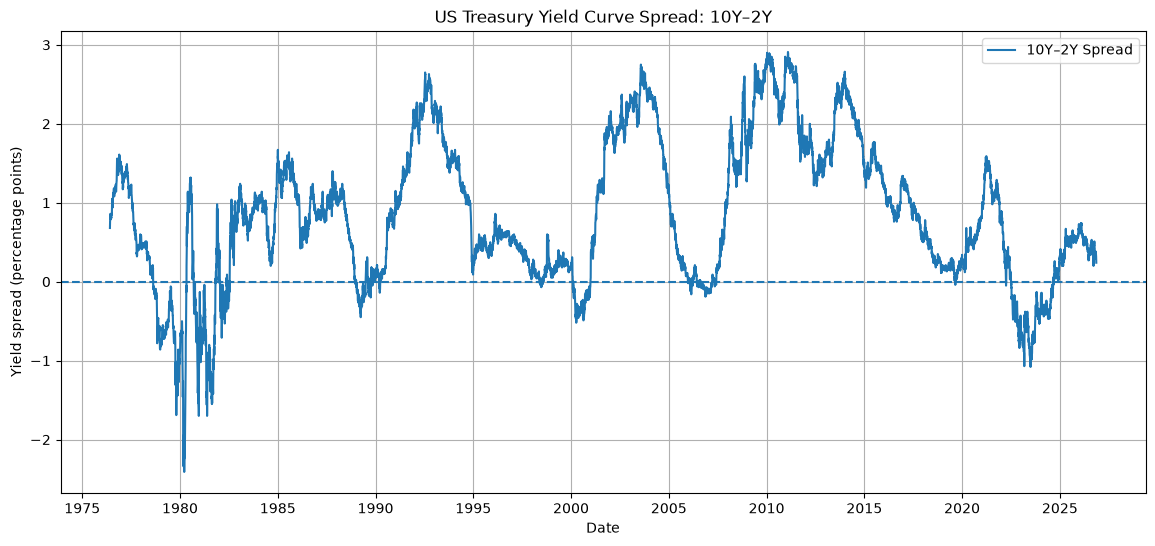

In [9]:
# Plot the 10Y–2Y yield spread
plt.figure(figsize=(14, 6))

plt.plot(clean_data["observation_date"], clean_data["yield_spread"], label="10Y–2Y Spread")

# Add a horizontal zero line
plt.axhline(y=0, linestyle="--")
# Show date labels every 5 years
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.title("US Treasury Yield Curve Spread: 10Y–2Y")
plt.xlabel("Date")
plt.ylabel("Yield spread (percentage points)")
plt.legend()
plt.grid(True)

plt.show()

In [29]:
#NEXT:turn your daily Treasury data into a monthly interest-rate volatility indicator
monthly_volatility_2 = (
    clean_data
    .set_index("observation_date")["DGS2_change"]
    .resample("ME")   #groups the daily observations into calendar months.
    .std()
)

monthly_volatility_10 = (
    clean_data
    .set_index("observation_date")["DGS10_change"]
    .resample("ME")   #groups the daily observations into calendar months.
    .std()
)

# Combine 2-year and 10-year monthly volatility
monthly_volatility = pd.concat(
    [monthly_volatility_2, monthly_volatility_10],
    axis=1
)

# Rename columns
monthly_volatility.columns = [
    "DGS2_volatility",
    "DGS10_volatility"
]

# Display the latest monthly observations
monthly_volatility.tail().round(2)

,DGS2_volatility,DGS10_volatility
observation_date,,
2026-07-31,0.04,0.04
2026-08-31,0.05,0.05
2026-09-30,0.06,0.05
2026-10-31,0.05,0.05
2026-11-30,0.09,0.07


In [11]:
#another indicator relevant to our project: the ICE BofA MOVE Index - measures implied vol US Treasury market, derived from options prices.
#DGS2/DGS10 volatility: how much yields actually moved.
#MOVE Index: how much volatility the options market priced in for future
#We want to test whether either measure helps explain changes in Rates desk revenue.
#https://uk.investing.com/indices/ice-bofaml-move-historical-data
#%pip install openpyxl
# Import MOVE historical data
move_data = pd.read_excel(r"C:\Users\User\OneDrive\Documents\Project\ICE BofAML MOVE Price Data.xlsx")

# Inspect MOVE dataset structure
move_data.info()

# Check column names
print(move_data.columns.tolist())

# Convert Excel serial numbers into proper dates
move_data["Date"] = pd.to_datetime(
    move_data["Date"],
    unit="D",
    origin="1899-12-30"
)

# Check earliest and latest observations
print(move_data["Date"].min())
print(move_data["Date"].max())

move_data = move_data.sort_values("Date").reset_index(drop=True)   #sort chornological old to new
move_data.tail()



<class 'pandas.DataFrame'>
RangeIndex: 5950 entries, 0 to 5949
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      5950 non-null   int64  
 1   Price     5950 non-null   float64
 2   Open      5950 non-null   float64
 3   High      5950 non-null   float64
 4   Low       5950 non-null   float64
 5   Vol.      0 non-null      float64
 6   Change %  5950 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 325.5 KB
['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %']
2002-11-13 00:00:00
2026-11-13 00:00:00


,Date,Price,Open,High,Low,Vol.,Change %
5945,2026-11-06,92.77,97.92,98.11,92.04,NaN,-0.0526
5946,2026-11-09,85.98,92.77,92.77,85.98,NaN,-0.0732
5947,2026-11-10,92.43,85.98,94.39,85.98,NaN,0.0750
5948,2026-11-12,98.43,92.43,98.48,92.43,NaN,0.0649
5949,2026-11-13,98.79,98.43,101.76,98.43,NaN,0.0037


In [12]:
move_data = move_data[["Date", "Price"]].copy()

move_data = move_data.rename(columns={"Price": "MOVE"})

move_data.tail()

,Date,MOVE
5945,2026-11-06,92.77
5946,2026-11-09,85.98
5947,2026-11-10,92.43
5948,2026-11-12,98.43
5949,2026-11-13,98.79


In [28]:
#We'll use the monthly average MOVE level as our first measure of interest-rate uncertainty.

monthly_move = (
    move_data
    .set_index("Date")["MOVE"]
    .resample("ME")
    .mean()
    .to_frame("MOVE_monthly_average"))

monthly_move.tail().round(2)

,MOVE_monthly_average
Date,
2026-07-31,73.15
2026-08-31,73.52
2026-09-30,85.83
2026-10-31,101.77
2026-11-30,95.61


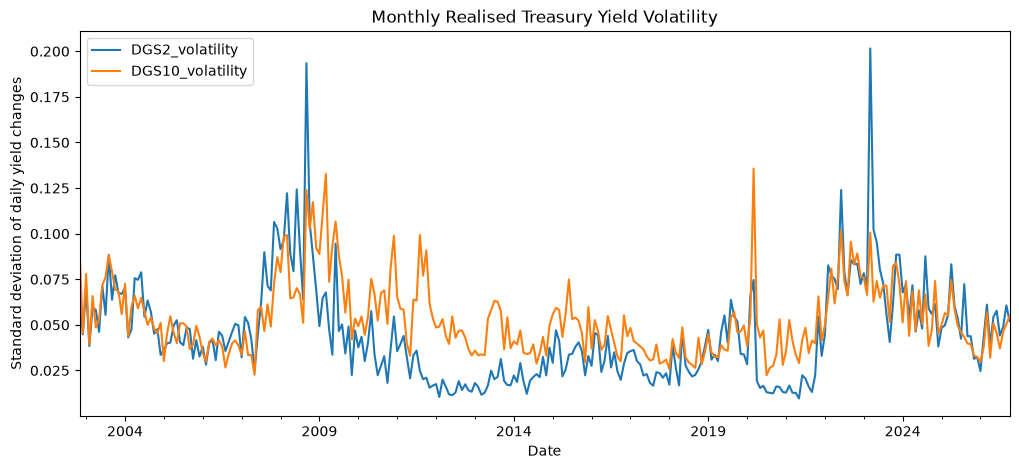

In [15]:
monthly_market_data[
    ["DGS2_volatility", "DGS10_volatility"]
].plot(
    figsize=(12, 5),
    title="Monthly Realised Treasury Yield Volatility")

plt.ylabel("Standard deviation of daily yield changes")
plt.xlabel("Date")
plt.show()

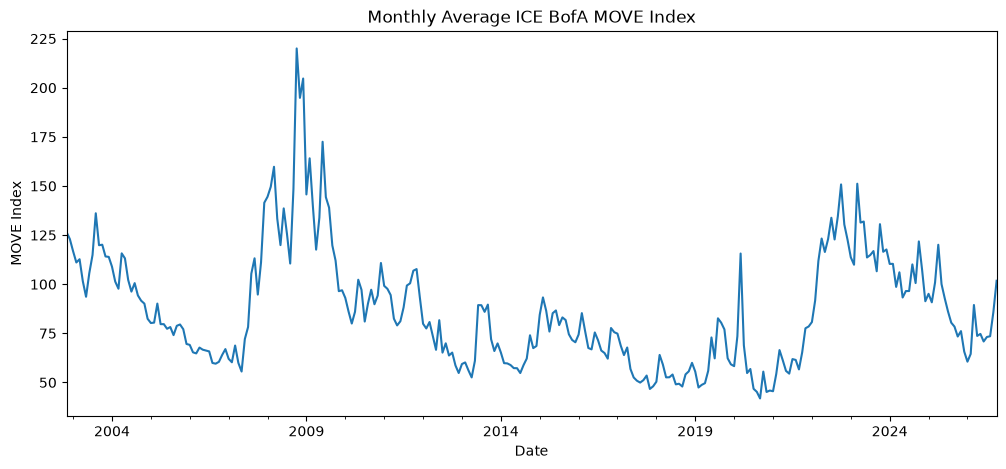

In [16]:
monthly_market_data["MOVE_monthly_average"].plot(
    figsize=(12, 5),
    title="Monthly Average ICE BofA MOVE Index")

plt.ylabel("MOVE Index")
plt.xlabel("Date")
plt.show()

In [17]:
monthly_market_data.corr().round(2)

,DGS2_volatility,DGS10_volatility,MOVE_monthly_average
DGS2_volatility,1.00,0.68,0.75
DGS10_volatility,0.68,1.00,0.84
MOVE_monthly_average,0.75,0.84,1.00


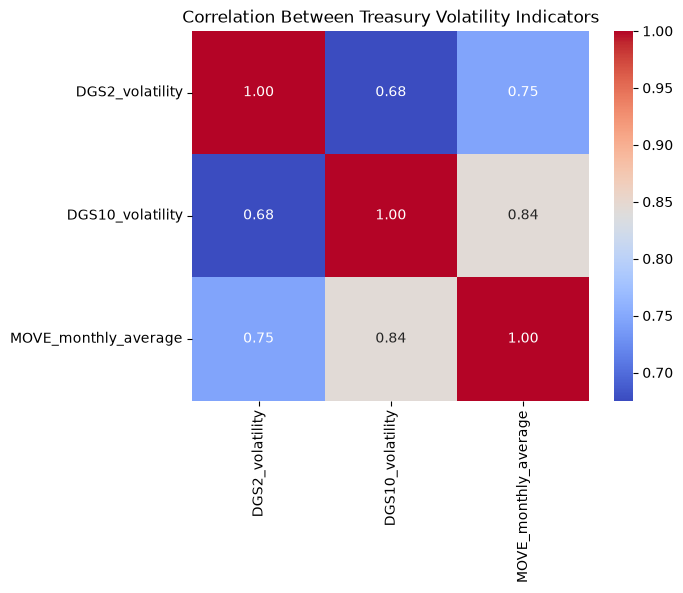

In [20]:
#%pip install seaborn
import seaborn as sns

sns.heatmap(
    monthly_market_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Treasury Volatility Indicators")
plt.show()

In [22]:
#Monthly sum of daily yield changes / net movement in yields gives us a measure of directional repricing.
monthly_yield_changes = (
    clean_data
    .set_index("observation_date")
    [["DGS2_change", "DGS10_change"]]
    .resample("ME")
    .sum())

monthly_yield_changes.columns = [
    "DGS2_monthly_change",
    "DGS10_monthly_change"]

monthly_yield_changes = monthly_yield_changes[
    monthly_yield_changes.index < "2026-11-01"
]
monthly_yield_changes.tail()

,DGS2_monthly_change,DGS10_monthly_change
observation_date,,
2026-06-30,0.16,-0.01
2026-07-31,0.14,0.31
2026-08-31,0.06,0.00
2026-09-30,0.54,0.54
2026-10-31,-0.32,-0.35


In [27]:
monthly_market_data = monthly_volatility.join(
    monthly_move,
    how="inner")

monthly_market_data = monthly_market_data[
    monthly_market_data.index < "2026-11-01"]

monthly_yield_changes = monthly_yield_changes[
    monthly_yield_changes.index < "2026-11-01"]

market_features = monthly_market_data.join(
    monthly_yield_changes,
    how="inner")
market_features.tail().round(2)

,DGS2_volatility,DGS10_volatility,MOVE_monthly_average,DGS2_monthly_change,DGS10_monthly_change
observation_date,,,,,
2026-06-30,0.06,0.05,70.86,0.16,-0.01
2026-07-31,0.04,0.04,73.15,0.14,0.31
2026-08-31,0.05,0.05,73.52,0.06,0.00
2026-09-30,0.06,0.05,85.83,0.54,0.54
2026-10-31,0.05,0.05,101.77,-0.32,-0.35


In [37]:
#Variance Inflation Factor (VIF) to check multicollinearity
#R-squared tells you how much of the variation in MOVE can be explained by those four variables together
#%pip install statsmodels
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import pandas as pd

# Add an intercept to the explanatory variables
X = sm.add_constant(market_features)   #adds a column of 1s to your data

# Calculate VIF for each market variable
vif_data = pd.DataFrame()
vif_data["Variable"] = market_features.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(1, X.shape[1])
]

vif_data.round(2)

#All five variables have VIF below 5.This suggests that, although the indicators overlap, not strong evidence of problematic multicollinearity.
#when two explanatory variables contain too much of the same info, the regression struggles to distinguish their individual contributions.

,Variable,VIF
0,DGS2_volatility,2.31
1,DGS10_volatility,3.53
2,MOVE_monthly_average,4.32
3,DGS2_monthly_change,2.55
4,DGS10_monthly_change,2.51
